# Will the next three hours be a geomagnetic storm?

Forecast whether Kp, three hours from now, will reach 5. That is the NOAA G1 threshold: the usual definition of a geomagnetic storm, and the point at which satellite operators start caring about drag, charging, and whether to maneuver.

The inputs are the solar wind already measured upstream of Earth. The label is future Kp. Current Kp is not a model feature. It is only the persistence baseline the model has to beat.


## Why this question

a probability an operator that can be acted on: drag, charging, dose, and link conditions for a specific orbit. The public problem underneath that decision is short-horizon geomagnetic activity. Kp is the index NOAA puts on the G-scale. Kp of 5 or more is about one hour in thirty, which is where the class imbalance comes from.

Two other problems are real and are not this notebook. Flare prediction needs solar images and a split by active region. Thermospheric density is closer to drag, but a density model fed with observed ap is mostly rewriting the index, and it will see a forecast of ap in production. 


In [2]:
%matplotlib inline

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier


In [3]:
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Open this notebook from the SpaceWeather repository.")


ROOT = find_root()
DATA_DIR = ROOT / "data"
ARTIFACTS = ROOT / "artifacts"
DATA_DIR.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)

OMNI_PATH = DATA_DIR / "omni_solar_wind_parameters.parquet"

# Cuts are fixed before any fitting. Validation is for early stopping and the
# decision threshold only. Six hours matches the longest lag.
TRAIN_START = pd.Timestamp("1995-01-01", tz="UTC")
TRAIN_END = pd.Timestamp("2017-01-01", tz="UTC")
VAL_END = pd.Timestamp("2021-01-01", tz="UTC")
GAP = pd.Timedelta(hours=6)
RANDOM_STATE = 0


## Load data

### Local OMNI parquet

[OMNI2](https://omniweb.gsfc.nasa.gov/html/ow_data.html) is the standard near-Earth solar-wind record. NASA time-shifts ACE, Wind, and the older monitors to the bow shock and puts Kp, ap, Dst, and F10.7 on the same hour.

The file on disk is `data/omni_solar_wind_parameters.parquet`. Missing measurements are already NaN. Kp is stored as Kp times 10: `50` is Kp 5, `47` is Kp 5−, `53` is Kp 5+. G1 starts at Kp 5, so the storm line is 50, not 47.

This extract has no spacecraft id. Later cells map a missing id to `unknown` and leave that column out of the model. The loader keeps the columns used below and renames them to those names. Hours before 1995 are dropped.


In [4]:
# Parquet names -> the names the rest of this notebook already uses.
COLUMN_MAP = {
    "datetime": "time",
    "b_magnitude_avg_nt": "b_mag",
    "bx_gse_nt": "bx",
    "by_gsm_nt": "by_gsm",
    "bz_gsm_nt": "bz_gsm",
    "proton_temperature_k": "temperature",
    "proton_density_cm3": "density",
    "flow_speed_kms": "speed",
    "flow_pressure_npa": "pressure",
    "electric_field_mvpm": "ey",
    "kp_index": "kp_raw",
    "dst_index_nt": "dst",
    "ae_index_nt": "ae",
    "ap_index_nt": "ap",
    "f107_index_sfu": "f107",
}


def read_omni(path: Path) -> pd.DataFrame:
    """Load the local hourly OMNI parquet and keep the modeling columns."""
    frame = pd.read_parquet(path)
    missing = [name for name in COLUMN_MAP if name not in frame.columns]
    if missing:
        raise KeyError(f"Parquet is missing columns: {missing}")
    frame = frame.loc[:, list(COLUMN_MAP)].rename(columns=COLUMN_MAP)
    frame["time"] = pd.to_datetime(frame["time"], utc=True)
    frame = frame.loc[frame["time"] >= TRAIN_START].copy()
    frame = frame.sort_values("time").drop_duplicates("time", keep="last")
    frame["imf_sc"] = np.nan
    return frame.reset_index(drop=True)


raw = read_omni(OMNI_PATH)
print(f"{len(raw):,} hourly rows from {raw['time'].min()} to {raw['time'].max()}")


280,512 hourly rows from 1995-01-01 00:00:00+00:00 to 2026-12-31 23:00:00+00:00


## Inspect

The maxima are the tell: solar-wind speed does not reach 9999 km/s, and Kp does not reach 99.


In [6]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280512 entries, 0 to 280511
Data columns (total 16 columns):
 #   Column       Non-Null Count   Dtype              
---  ------       --------------   -----              
 0   time         280512 non-null  datetime64[us, UTC]
 1   b_mag        276933 non-null  float64            
 2   bx           276933 non-null  float64            
 3   by_gsm       276907 non-null  float64            
 4   bz_gsm       276907 non-null  float64            
 5   temperature  272480 non-null  float64            
 6   density      271935 non-null  float64            
 7   speed        276617 non-null  float64            
 8   pressure     271927 non-null  float64            
 9   ey           276238 non-null  float64            
 10  kp_raw       278400 non-null  float64            
 11  dst          278414 non-null  float64            
 12  ae           277896 non-null  float64            
 13  ap           278400 non-null  float64            
 14  f107

In [7]:
raw.head()

,time,b_mag,bx,by_gsm,bz_gsm,temperature,density,speed,pressure,ey,kp_raw,dst,ae,ap,f107,imf_sc
0,1995-01-01 00:00:00+00:00,4.0,-0.6,3.6,-1.2,15816.0,16.3,315.0,2.87,0.38,10.0,-2.0,32.0,4.0,72.9,NaN
1,1995-01-01 01:00:00+00:00,3.0,-0.9,2.6,-0.7,15601.0,18.8,315.0,3.28,0.22,10.0,3.0,38.0,4.0,72.9,NaN
2,1995-01-01 02:00:00+00:00,3.2,0.5,1.8,0.0,20703.0,19.3,320.0,3.46,-0.00,10.0,6.0,34.0,4.0,72.9,NaN
3,1995-01-01 03:00:00+00:00,4.3,-3.2,2.4,0.7,25094.0,16.4,317.0,2.90,-0.22,0.0,5.0,36.0,0.0,72.9,NaN
4,1995-01-01 04:00:00+00:00,4.8,-4.3,2.1,0.5,25604.0,14.5,313.0,2.51,-0.16,0.0,3.0,31.0,0.0,72.9,NaN


In [8]:
raw.describe().T


,count,mean,std,min,25%,50%,75%,max
b_mag,276933.0,5.848910,3.097885,0.40,3.90,5.20,6.90,68.90
bx,276933.0,-0.001756,3.473111,-40.80,-2.50,0.00,2.50,34.80
by_gsm,276907.0,-0.021617,3.828464,-43.10,-2.40,-0.10,2.40,67.60
bz_gsm,276907.0,-0.063953,3.027513,-57.80,-1.60,-0.10,1.40,58.90
temperature,272480.0,94521.298899,94300.585964,3221.00,36568.00,68011.00,123296.25,6632456.00
density,271935.0,6.259256,5.031124,0.10,3.10,4.80,7.70,137.20
speed,276617.0,428.496499,100.342308,228.00,354.00,406.00,482.00,1189.00
pressure,271927.0,2.024269,1.703318,0.03,1.13,1.63,2.40,71.04
ey,276238.0,0.031081,1.414245,-63.26,-0.59,0.03,0.65,47.11
kp_raw,278400.0,18.308136,13.476485,0.00,7.00,17.00,27.00,90.00


## Missing values are sentinels, and zeros in Bz are real

OMNI fills a gap with a field of nines. Treating those as measurements would invent a solar wind of 9999 km/s. Replacing every zero would do the opposite kind of damage: Bz of 0 nT is the boundary between northward and southward field, and southward Bz is the driver that opens the magnetosphere.

What each column gets, decided before the replacement:

- Bz, By, Bx, field magnitude, speed, density, temperature, pressure: sentinel to NaN, then drop the row. Imputing Bz invents the cause of the storm.
- F10.7 is one daily measurement copied onto 24 hours. Forward-fill gaps shorter than a day. Drop anything still missing.
- Kp, and the label built from Kp: never impute. A sentinel becomes a dropped row.
- Spacecraft id 99 means no magnetometer. Map the remaining integer codes to names, fit a one-hot encoder on the training years only, save it, and then leave it out of the model. ACE versus Wind is a proxy for which years are in the sample.


In [9]:
SENTINELS = {
    "b_mag": 999.9,
    "bx": 999.9,
    "by_gsm": 999.9,
    "bz_gsm": 999.9,
    "temperature": 9_999_999.0,
    "density": 999.9,
    "speed": 9999.0,
    "pressure": 99.99,
    "ey": 999.99,
    "kp_raw": 99,
    "dst": 99999,
    "ae": 9999,
    "ap": 9999,
    "f107": 999.9,
    "imf_sc": 99,
}

In [10]:
def fill_mask(values, fill):
    numeric = pd.to_numeric(values, errors="coerce")
    return np.isclose(numeric, fill, rtol=0, atol=1e-2)


sentinel_report = pd.DataFrame(
    [
        {
            "column": column,
            "fill_value": fill,
            "n_fill": int(fill_mask(raw[column], fill).sum()),
        }
        for column, fill in SENTINELS.items()
    ]
)
sentinel_report["pct"] = 100 * sentinel_report["n_fill"] / len(raw)
sentinel_report


,column,fill_value,n_fill,pct
0,b_mag,999.90,0,0.0
1,bx,999.90,0,0.0
2,by_gsm,999.90,0,0.0
3,bz_gsm,999.90,0,0.0
4,temperature,9999999.00,0,0.0
5,density,999.90,0,0.0
6,speed,9999.00,0,0.0
7,pressure,99.99,0,0.0
8,ey,999.99,0,0.0
9,kp_raw,99.00,0,0.0


In [11]:
print(f"Bz exactly 0 nT: {(raw['bz_gsm'] == 0).sum():,} hours. Those stay.")
print("Kp encoding, smallest stored values:", sorted(raw["kp_raw"].dropna().unique())[:8])


Bz exactly 0 nT: 5,212 hours. Those stay.
Kp encoding, smallest stored values: [np.float64(0.0), np.float64(3.0), np.float64(7.0), np.float64(10.0), np.float64(13.0), np.float64(17.0), np.float64(20.0), np.float64(23.0)]


## Clean, build the clock, then build the label

Lags and the three-hour-ahead label are shifts on a complete hourly grid, taken after sentinels become NaN and before rows are dropped. Shifting after a drop would treat the next surviving row as "one hour later" even when a gap was in between.

The label is Kp at t+3 hours, divided by 10, then `storm = 1` when that value is at least 5. An onset is the first hour of a contiguous run of that label. Persistence will look strong on the hours after onset and weak on the onset itself.


In [12]:
IMF_NAMES = {
    1: "HEOS",
    3: "VELA 3",
    5: "OGO 5",
    10: "Prognoz 10",
    11: "ISEE 1",
    13: "ISEE 3",
    18: "IMP 1",
    28: "IMP 3",
    33: "AIMP 1",
    34: "IMP 4",
    35: "AIMP 2",
    41: "IMP 5",
    43: "IMP 6",
    44: "IMP 7",
    45: "IMP 8",
    47: "IMP 7",
    50: "IMP 8",
    51: "Wind",
    60: "Geotail",
    71: "ACE",
    97: "Merged LANL VELA",
    98: "Merged LANL IMP",
}

cleaned = raw.copy()
for column, fill in SENTINELS.items():
    cleaned.loc[fill_mask(cleaned[column], fill), column] = np.nan

cleaned = cleaned.set_index("time").sort_index()
hourly_index = pd.date_range(cleaned.index.min(), cleaned.index.max(), freq="h", tz="UTC")
hourly = cleaned.reindex(hourly_index)
hourly.index.name = "time"

# Daily F10.7: fill at most 23 missing hours, which is a gap shorter than a day.
hourly["f107"] = hourly["f107"].ffill(limit=23)

hourly["kp"] = hourly["kp_raw"] / 10.0
hourly["kp_in_3h"] = hourly["kp"].shift(-3)
hourly["storm"] = np.where(hourly["kp_in_3h"].notna(), (hourly["kp_in_3h"] >= 5).astype(float), np.nan)
previous_storm = hourly["storm"].shift(1)
hourly["onset"] = (
    (hourly["storm"] == 1) & previous_storm.fillna(0).eq(0) & hourly["storm"].notna()
).astype(float)

for lag in (1, 3, 6):
    hourly[f"bz_gsm_lag{lag}"] = hourly["bz_gsm"].shift(lag)
    hourly[f"speed_lag{lag}"] = hourly["speed"].shift(lag)

codes = pd.to_numeric(hourly["imf_sc"], errors="coerce").round()
hourly["imf_spacecraft"] = [
    IMF_NAMES.get(int(code), "unknown").strip() if pd.notna(code) else "unknown" for code in codes
]

FEATURE_COLS = [
    "bx",
    "by_gsm",
    "bz_gsm",
    "b_mag",
    "speed",
    "density",
    "temperature",
    "pressure",
    "f107",
    "bz_gsm_lag1",
    "bz_gsm_lag3",
    "bz_gsm_lag6",
    "speed_lag1",
    "speed_lag3",
    "speed_lag6",
]
REQUIRED = FEATURE_COLS + ["storm", "kp", "kp_in_3h", "onset"]

before = len(hourly)
df = hourly.dropna(subset=REQUIRED).copy()
df["storm"] = df["storm"].astype(int)
df["onset"] = df["onset"].astype(int)
df = df.reset_index()
print(f"Dropped {before - len(df):,} of {before:,} hours that were missing a driver, a lag, or the label.")
print(f"Modeling table: {len(df):,} hours, {df['time'].min()} to {df['time'].max()}")


Dropped 10,194 of 280,512 hours that were missing a driver, a lag, or the label.
Modeling table: 270,318 hours, 1995-01-01 06:00:00+00:00 to 2026-09-18 00:00:00+00:00


## Check again

Nulls in the modeling columns should now be zero. Time should be sorted, hourly, and unique. The storm rate should be a few percent. Kp is constant for three hours, so the number of independent labels is about a third of the row count.


In [13]:
print("Nulls in modeling columns:")
print(df[REQUIRED].isna().sum().to_string())
print()
print("dtypes:")
print(df[REQUIRED + ["imf_spacecraft"]].dtypes.to_string())
print()
assert df["time"].is_monotonic_increasing
assert df["time"].duplicated().sum() == 0
gaps = df["time"].diff().dropna()
print(f"Median spacing: {gaps.median()}")
print(f"Rows with a gap longer than 1 hour behind them: {(gaps > pd.Timedelta(hours=1)).sum():,}")
print()
storm_rate = df["storm"].mean()
print(f"Storm rate: {storm_rate:.3%} ({df['storm'].sum():,} of {len(df):,} hours)")
print(f"Distinct 3-hour Kp bins: {df['time'].dt.floor('3h').nunique():,}")
print(f"Onset hours: {df['onset'].sum():,}")
print()
print(df["imf_spacecraft"].value_counts().to_string())


Nulls in modeling columns:
bx             0
by_gsm         0
bz_gsm         0
b_mag          0
speed          0
density        0
temperature    0
pressure       0
f107           0
bz_gsm_lag1    0
bz_gsm_lag3    0
bz_gsm_lag6    0
speed_lag1     0
speed_lag3     0
speed_lag6     0
storm          0
kp             0
kp_in_3h       0
onset          0

dtypes:
bx                float64
by_gsm            float64
bz_gsm            float64
b_mag             float64
speed             float64
density           float64
temperature       float64
pressure          float64
f107              float64
bz_gsm_lag1       float64
bz_gsm_lag3       float64
bz_gsm_lag6       float64
speed_lag1        float64
speed_lag3        float64
speed_lag6        float64
storm               int64
kp                float64
kp_in_3h          float64
onset               int64
imf_spacecraft     object

Median spacing: 0 days 01:00:00
Rows with a gap longer than 1 hour behind them: 827

Storm rate: 2.781% (7,517 of 270,31

## Where the label sits in each driver

These histograms use every modeling row. They are a picture, not a fit, so the test years are allowed in the drawing. The model later trains only on the training years.

Storm hours should sit at more negative Bz and higher speed, with a lot of overlap. That overlap is why a threshold is a baseline rather than the answer.


Quiet hours: 262,801    Storm hours: 7,517


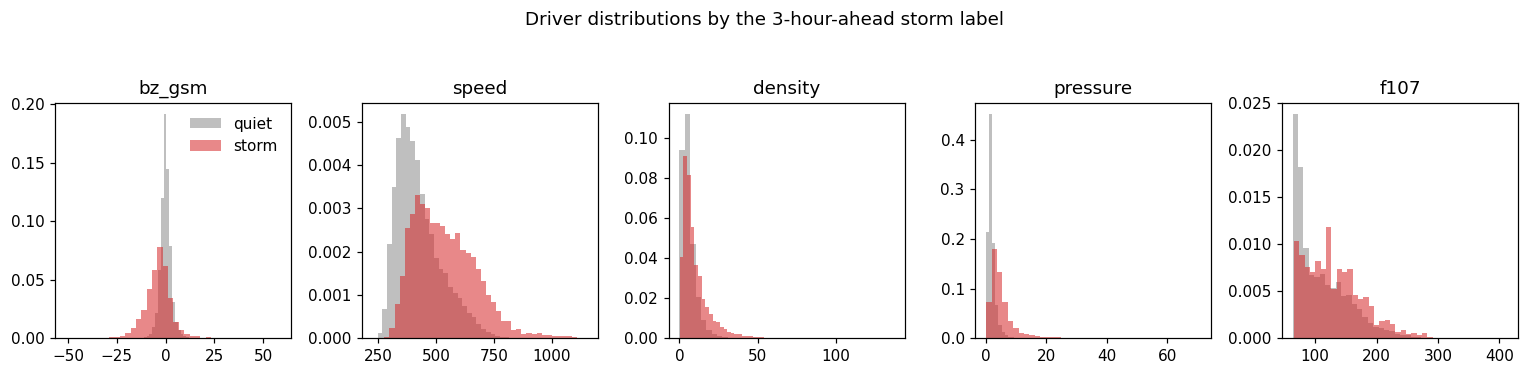

In [14]:
print(f"Quiet hours: {(df['storm'] == 0).sum():,}    Storm hours: {(df['storm'] == 1).sum():,}")

picture_cols = ["bz_gsm", "speed", "density", "pressure", "f107"]
fig, axes = plt.subplots(1, len(picture_cols), figsize=(14, 3.2))
for ax, column in zip(axes, picture_cols):
    for label, name, color in [(0, "quiet", "0.55"), (1, "storm", "C3")]:
        ax.hist(
            df.loc[df["storm"] == label, column],
            bins=40,
            density=True,
            alpha=0.55,
            label=name,
            color=color,
        )
    ax.set_title(column)
axes[0].legend(frameon=False)
fig.suptitle("Driver distributions by the 3-hour-ahead storm label", y=1.05)
fig.tight_layout()
plt.show()


## Which columns are allowed in the model

Kept: the upstream drivers, their 1-, 3-, and 6-hour lags, and F10.7. F10.7 is the slow solar-cycle baseline. The lags are recent solar wind, not recent Kp.

Left out on purpose:

- Kp, ap, Dst, AE, AL, AU. They are the geomagnetic response. Using them to predict Kp is the autocorrelation trap.
- Ey. It is defined as `-V * Bz` (with a unit factor). It adds no information once speed and Bz are present.
- Spacecraft id. Encoded and saved below, after the training cut exists, then excluded.

The correlation matrix is computed on the training years only.


Correlation of Ey with -V * Bz on the training years: 1.000


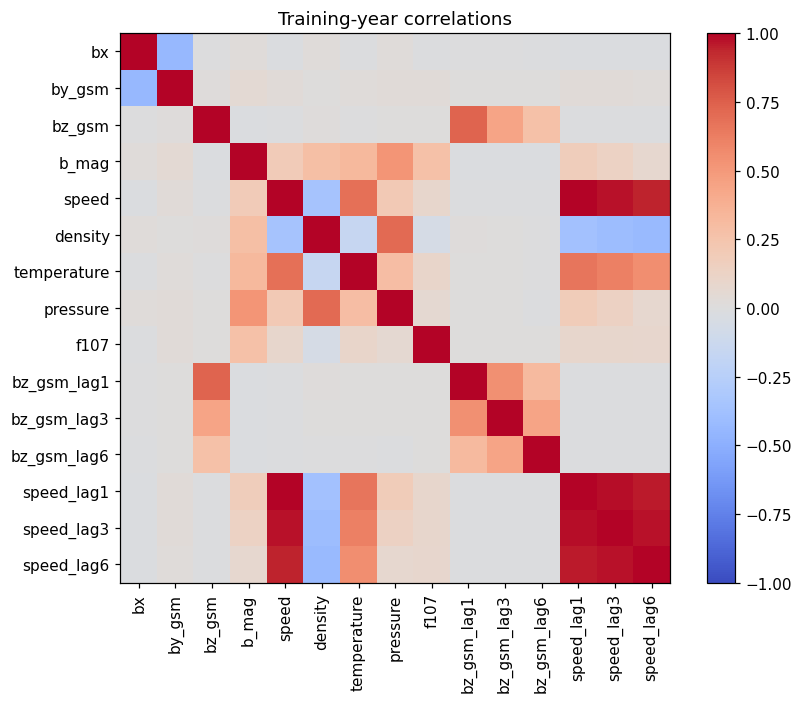

In [15]:
train_years = df[(df["time"] >= TRAIN_START) & (df["time"] < TRAIN_END)]
ey_check = train_years.dropna(subset=["ey"])
reconstructed = -ey_check["speed"] * ey_check["bz_gsm"] * 1e-3
print(f"Correlation of Ey with -V * Bz on the training years: {ey_check['ey'].corr(reconstructed):.3f}")

corr = train_years[FEATURE_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_COLS)))
ax.set_yticks(range(len(FEATURE_COLS)))
ax.set_xticklabels(FEATURE_COLS, rotation=90)
ax.set_yticklabels(FEATURE_COLS)
fig.colorbar(image, ax=ax, fraction=0.046)
ax.set_title("Training-year correlations")
fig.tight_layout()
plt.show()


## Split by time, with a gap

There is no geographic region in this table. The structural unit is the storm. A random split, or a split that puts 14:00 in train and 15:00 in test, lets the same event teach and grade the model.

- Train: 1995 through 2016, ending 6 hours early
- Validation: 2017 through 2020, inset by 6 hours at both ends. Early stopping and the decision threshold use only this block.
- Test: 2021 onward, starting 6 hours late. This block contains the February 2022 Starlink losses and the May 2024 Gannon storm.

The encoder is fit on the training rows and written to `artifacts/`. It is not a feature.


In [16]:
def slice_period(frame, start, end):
    return frame[(frame["time"] >= start) & (frame["time"] < end)].copy()


train = slice_period(df, TRAIN_START, TRAIN_END - GAP)
val = slice_period(df, TRAIN_END + GAP, VAL_END - GAP)
test = slice_period(df, VAL_END + GAP, df["time"].max() + GAP)

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(
        f"{name:12} {part['time'].min()}  to  {part['time'].max()}  "
        f"n={len(part):,}  storms={part['storm'].sum():,}  rate={part['storm'].mean():.3%}"
    )

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train[["imf_spacecraft"]])
encoder_path = ARTIFACTS / "imf_spacecraft_encoder.joblib"
joblib.dump(encoder, encoder_path)
encoded = encoder.transform(train[["imf_spacecraft"]])
print()
print(f"Saved {encoder_path.name}")
print("Categories:", list(encoder.categories_[0]))
print(f"Encoded training shape: {encoded.shape}. This matrix is not passed to the model.")


train        1995-01-01 06:00:00+00:00  to  2016-12-31 17:00:00+00:00  n=187,121  storms=5,707  rate=3.050%
validation   2017-01-01 06:00:00+00:00  to  2020-12-31 17:00:00+00:00  n=34,930  storms=369  rate=1.056%
test         2021-01-01 06:00:00+00:00  to  2026-09-18 00:00:00+00:00  n=48,243  storms=1,441  rate=2.987%

Saved imf_spacecraft_encoder.joblib
Categories: ['unknown']
Encoded training shape: (187121, 1). This matrix is not passed to the model.


## Two-dimensional PCA, fit on the training years

The scaler and the PCA see training rows only. The drawing subsamples the quiet class so the storm points are visible. Overlap here means the classes are not two blobs. A tree model does not need the components; the plot is about separability.


Variance explained: 30.8% and 16.0%


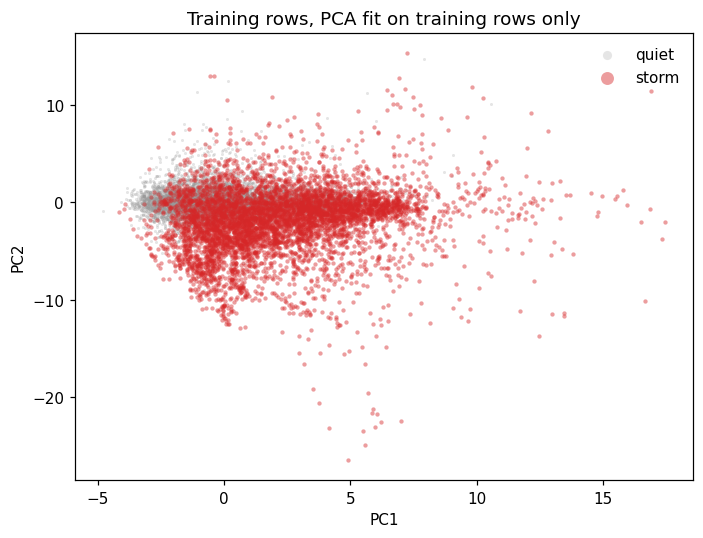

In [17]:
scaler = StandardScaler()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(scaler.fit_transform(train[FEATURE_COLS]))
print(f"Variance explained: {pca.explained_variance_ratio_[0]:.1%} and {pca.explained_variance_ratio_[1]:.1%}")

labels = train["storm"].to_numpy()
quiet = np.flatnonzero(labels == 0)
storms = np.flatnonzero(labels == 1)
rng = np.random.default_rng(RANDOM_STATE)
show_quiet = rng.choice(quiet, size=min(8000, len(quiet)), replace=False)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(components[show_quiet, 0], components[show_quiet, 1], s=4, c="0.6", alpha=0.25, label="quiet", linewidths=0)
ax.scatter(components[storms, 0], components[storms, 1], s=8, c="C3", alpha=0.45, label="storm", linewidths=0)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Training rows, PCA fit on training rows only")
ax.legend(frameon=False, markerscale=3)
fig.tight_layout()
plt.show()


## Do the splits still look like the same problem?

The test years are solar maximum of cycle 25. F10.7 and the storm rate should shift. If they do, a model that memorized the training base rate will be miscalibrated on the test set, which is the right thing to notice before trusting a score.


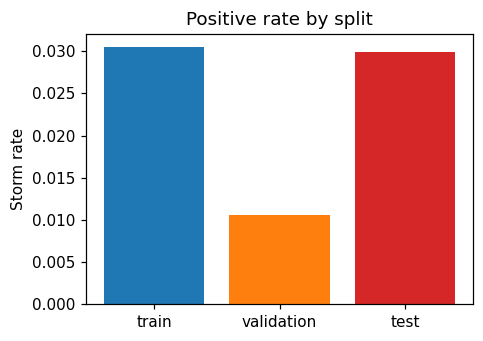

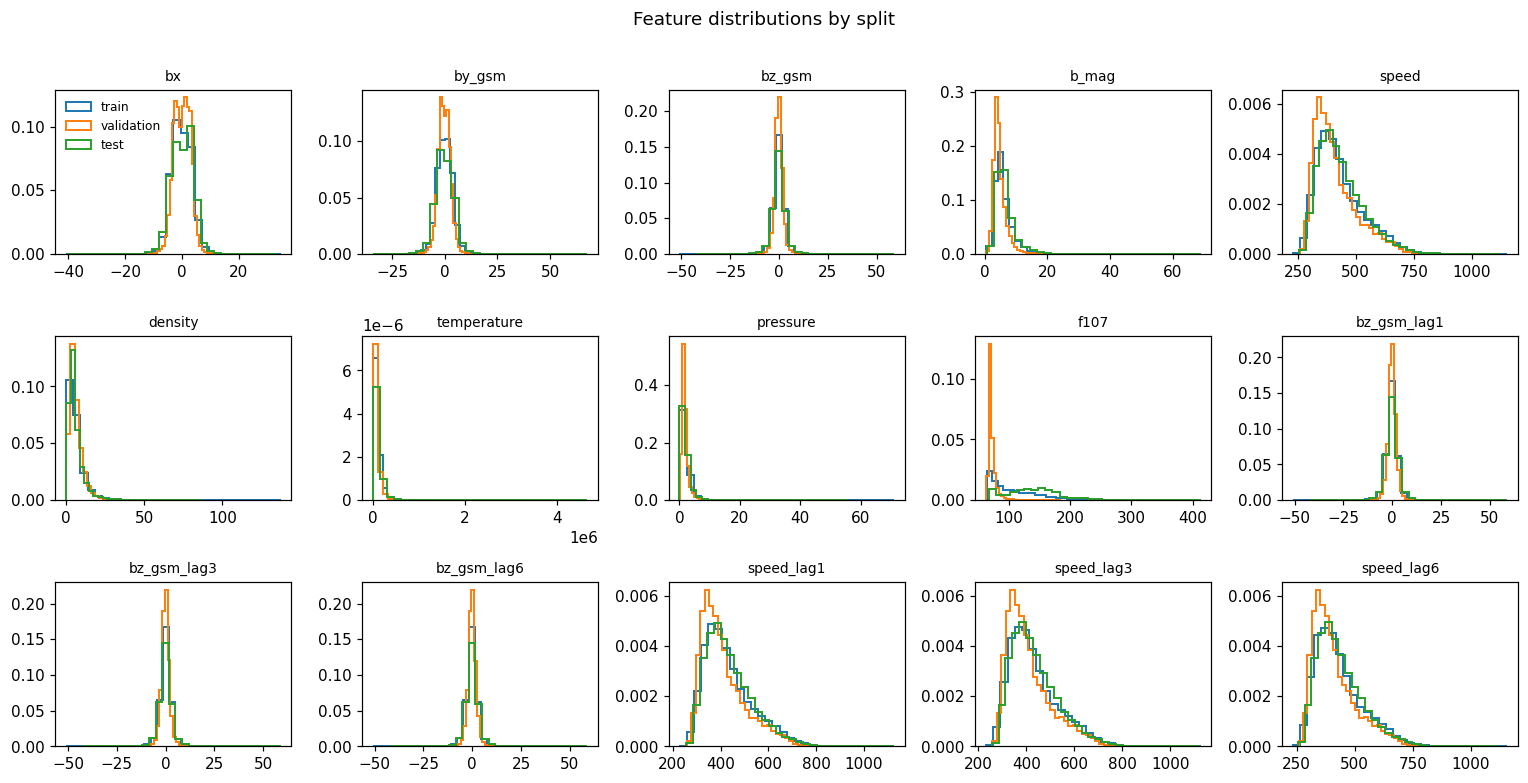

In [18]:
split_frames = {"train": train, "validation": val, "test": test}
rates = [part["storm"].mean() for part in split_frames.values()]
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(list(split_frames), rates, color=["C0", "C1", "C3"])
ax.set_ylabel("Storm rate")
ax.set_title("Positive rate by split")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(14, 7), sharex=False)
for ax, column in zip(axes.ravel(), FEATURE_COLS):
    for name, part in split_frames.items():
        ax.hist(part[column], bins=30, density=True, histtype="step", linewidth=1.3, label=name)
    ax.set_title(column, fontsize=9)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Feature distributions by split", y=1.01)
fig.tight_layout()
plt.show()


## Baselines, then a boosted tree

Persistence predicts a storm whenever the current Kp is already at least 5. It is allowed to see Kp. The model is not. This is the number to beat, and it cheats on every hour after a storm has already started.

The physics baseline is a cut on southward Bz plus a minimum speed. Both cuts are chosen on the validation block to maximize the true skill score, `TPR - FPR`, and then frozen.

XGBoost is the first model because the coupling is an interaction: fast wind matters much more when Bz is south. `scale_pos_weight` is the training negative/positive ratio. Early stopping watches validation log loss. The probability cut is also chosen on validation for true skill score, not left at 0.5.


In [19]:
def skill_counts(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    return int(tp), int(fp), int(fn), int(tn)


def true_skill_score(y_true, y_pred):
    tp, fp, fn, tn = skill_counts(y_true, y_pred)
    tpr = tp / (tp + fn) if (tp + fn) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    return tpr - fpr


def choose_probability_threshold(y_true, proba):
    best_threshold, best_score = 0.5, -np.inf
    for threshold in np.linspace(0.05, 0.95, 91):
        score = true_skill_score(y_true, proba >= threshold)
        if score > best_score:
            best_threshold, best_score = float(threshold), float(score)
    return best_threshold, best_score


def make_model(y):
    positives = float(np.sum(np.asarray(y) == 1))
    negatives = float(np.sum(np.asarray(y) == 0))
    return XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=negatives / positives,
        early_stopping_rounds=30,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


best_physics = (-np.inf, None, None)
for speed_gate in (300, 350, 400, 450, 500, 550):
    for bz_cut in np.round(np.arange(-12, 0.25, 0.5), 2):
        pred = (val["bz_gsm"] <= bz_cut) & (val["speed"] >= speed_gate)
        score = true_skill_score(val["storm"], pred)
        if score > best_physics[0]:
            best_physics = (score, float(bz_cut), int(speed_gate))

physics_tss, bz_cut, speed_gate = best_physics
print(
    f"Validation physics rule: Bz <= {bz_cut:.1f} nT and speed >= {speed_gate} km/s "
    f"(TSS {physics_tss:.3f})"
)
print(
    f"Validation persistence TSS: "
    f"{true_skill_score(val['storm'], val['kp'] >= 5):.3f}"
)


Validation physics rule: Bz <= -1.0 nT and speed >= 400 km/s (TSS 0.426)
Validation persistence TSS: 0.417


Best iteration: 399 of 400


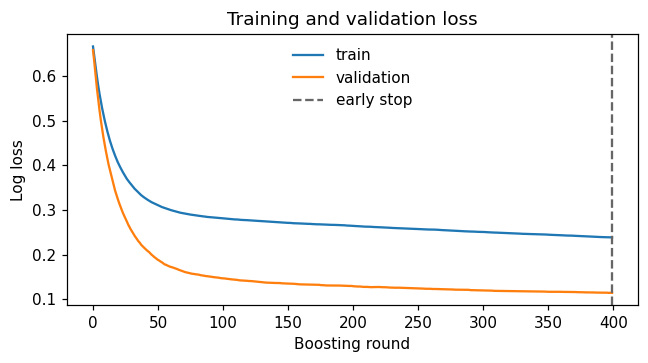

Frozen probability threshold: 0.15 (validation TSS 0.829)


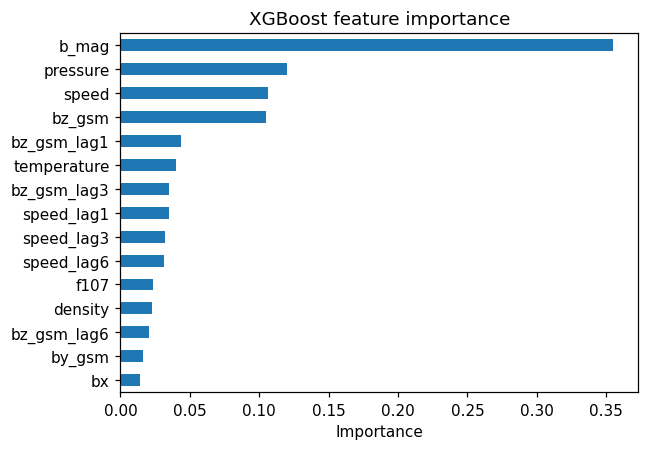

In [20]:
model = make_model(train["storm"])
model.fit(
    train[FEATURE_COLS],
    train["storm"],
    eval_set=[(train[FEATURE_COLS], train["storm"]), (val[FEATURE_COLS], val["storm"])],
    verbose=False,
)
print(f"Best iteration: {model.best_iteration} of {model.n_estimators}")

history = model.evals_result()
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(history["validation_0"]["logloss"], label="train")
ax.plot(history["validation_1"]["logloss"], label="validation")
ax.axvline(model.best_iteration, color="0.4", linestyle="--", label="early stop")
ax.set_xlabel("Boosting round")
ax.set_ylabel("Log loss")
ax.set_title("Training and validation loss")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

val_proba = model.predict_proba(val[FEATURE_COLS])[:, 1]
proba_threshold, val_tss = choose_probability_threshold(val["storm"], val_proba)
print(f"Frozen probability threshold: {proba_threshold:.2f} (validation TSS {val_tss:.3f})")

importance = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.2))
importance.plot.barh(ax=ax, color="C0")
ax.set_title("XGBoost feature importance")
ax.set_xlabel("Importance")
fig.tight_layout()
plt.show()


## Test the frozen rules

Nothing in this section is allowed to move the threshold. The curves are for the boosted model. Persistence and the Bz rule are single operating points, because they are not scores we sweep on the test set.

True skill score, precision, and recall are the decision numbers. ROC and PR are both drawn; PR is the one that does not get flattered by the quiet hours. The Brier score and the reliability diagram ask whether the probability itself means what it says. 

Onset recall uses only the first hour of each storm in the test block. That is where persistence has not yet been handed the answer.


In [21]:
scored = test.copy()
scored["persist_pred"] = (scored["kp"] >= 5).astype(int)
scored["physics_pred"] = ((scored["bz_gsm"] <= bz_cut) & (scored["speed"] >= speed_gate)).astype(int)
scored["proba"] = model.predict_proba(scored[FEATURE_COLS])[:, 1]
scored["xgb_pred"] = (scored["proba"] >= proba_threshold).astype(int)


def metric_row(name, y_true, y_pred, proba=None):
    tp, fp, fn, tn = skill_counts(y_true, y_pred)
    row = {
        "model": name,
        "tss": true_skill_score(y_true, y_pred),
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "hits": tp,
        "false_alarms": fp,
        "misses": fn,
    }
    if proba is not None:
        row["roc_auc"] = roc_auc_score(y_true, proba)
        row["pr_auc"] = average_precision_score(y_true, proba)
        row["brier"] = brier_score_loss(y_true, proba)
    return row


metrics = pd.DataFrame(
    [
        metric_row("persistence", scored["storm"], scored["persist_pred"]),
        metric_row("bz threshold", scored["storm"], scored["physics_pred"]),
        metric_row("xgboost", scored["storm"], scored["xgb_pred"], scored["proba"]),
    ]
)
metrics


,model,tss,precision,recall,hits,false_alarms,misses,roc_auc,pr_auc,brier
0,persistence,0.502953,0.519499,0.517696,746,690,695,NaN,NaN,NaN
1,bz threshold,0.401598,0.084213,0.603747,870,9461,571,NaN,NaN,NaN
2,xgboost,0.614981,0.079513,0.955586,1377,15941,64,0.938991,0.534027,0.097948


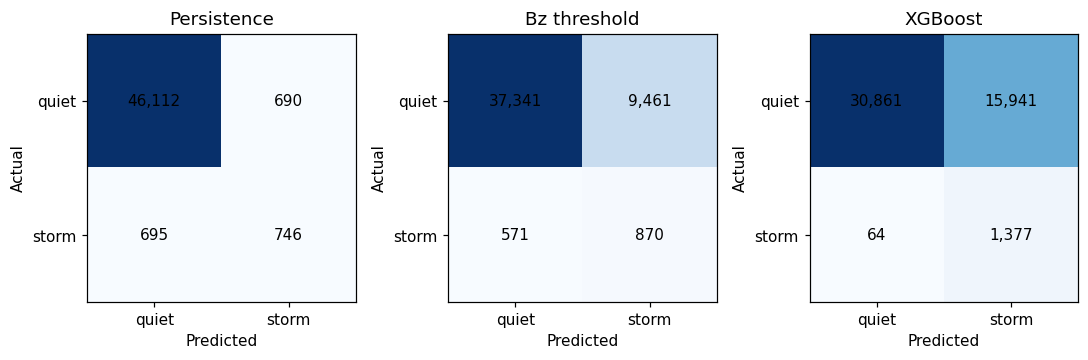

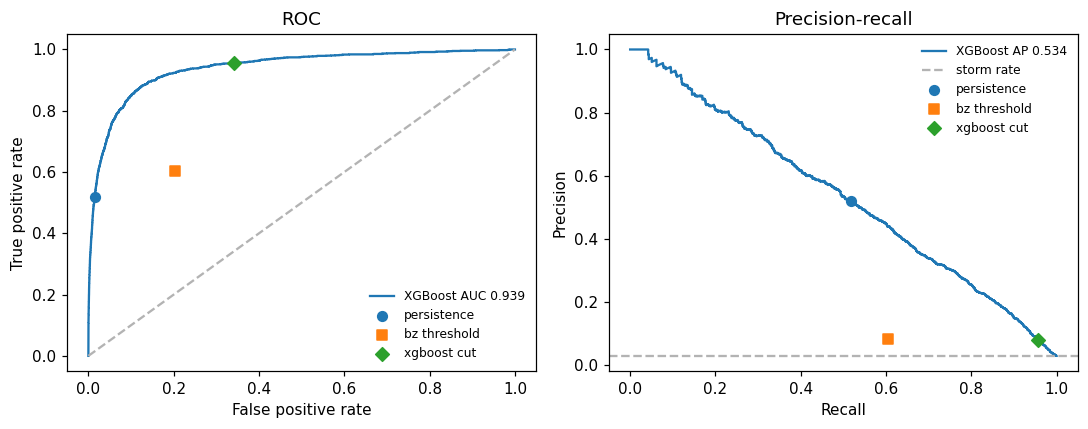

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, column, title in zip(
    axes,
    ["persist_pred", "physics_pred", "xgb_pred"],
    ["Persistence", "Bz threshold", "XGBoost"],
):
    matrix = confusion_matrix(scored["storm"], scored[column], labels=[0, 1])
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks([0, 1], ["quiet", "storm"])
    ax.set_yticks([0, 1], ["quiet", "storm"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:,}", ha="center", va="center")
fig.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(scored["storm"], scored["proba"])
precision, recall, _ = precision_recall_curve(scored["storm"], scored["proba"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr, label=f"XGBoost AUC {roc_auc_score(scored['storm'], scored['proba']):.3f}")
axes[0].plot([0, 1], [0, 1], color="0.7", linestyle="--")
axes[1].plot(recall, precision, label=f"XGBoost AP {average_precision_score(scored['storm'], scored['proba']):.3f}")
axes[1].axhline(scored["storm"].mean(), color="0.7", linestyle="--", label="storm rate")
for column, marker, label in [
    ("persist_pred", "o", "persistence"),
    ("physics_pred", "s", "bz threshold"),
    ("xgb_pred", "D", "xgboost cut"),
]:
    tp, fp, fn, tn = skill_counts(scored["storm"], scored[column])
    tpr_point = tp / (tp + fn) if (tp + fn) else 0
    fpr_point = fp / (fp + tn) if (fp + tn) else 0
    prec_point = tp / (tp + fp) if (tp + fp) else 0
    axes[0].scatter(fpr_point, tpr_point, marker=marker, s=40, label=label, zorder=3)
    axes[1].scatter(tpr_point, prec_point, marker=marker, s=40, label=label, zorder=3)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()



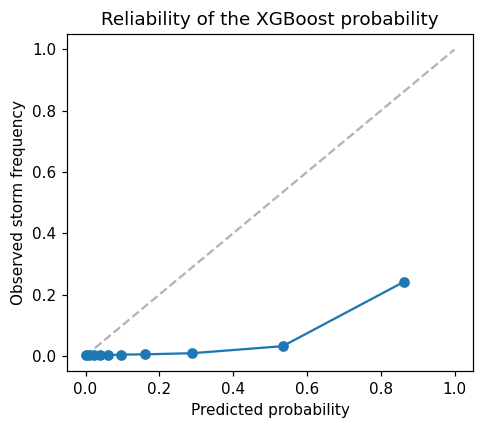

In [23]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(scored["storm"], scored["proba"], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0, 1], [0, 1], color="0.7", linestyle="--")
ax.plot(prob_pred, prob_true, marker="o")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Observed storm frequency")
ax.set_title("Reliability of the XGBoost probability")
fig.tight_layout()
plt.show()


In [24]:
onset = scored[scored["onset"] == 1]
onset_rows = []
for name, column in [("persistence", "persist_pred"), ("bz threshold", "physics_pred"), ("xgboost", "xgb_pred")]:
    onset_rows.append({"model": name, "onset_recall": onset[column].mean(), "n_onsets": len(onset)})
onset_table = pd.DataFrame(onset_rows)
onset_table


,model,onset_recall,n_onsets
0,persistence,0.000000,231
1,bz threshold,0.372294,231
2,xgboost,0.874459,231


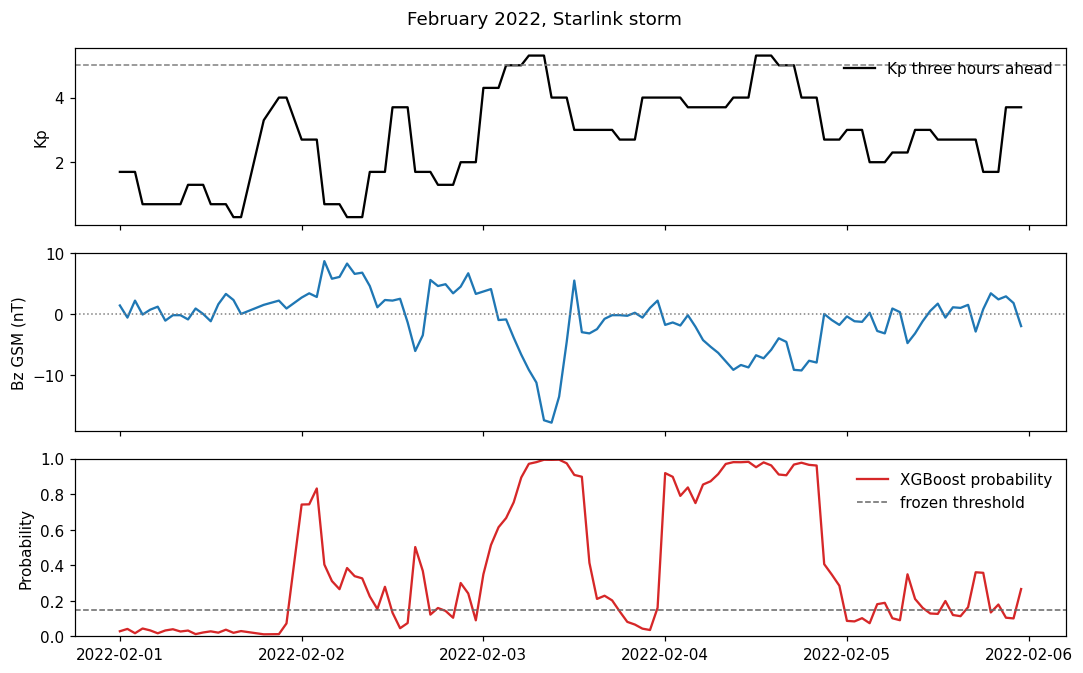

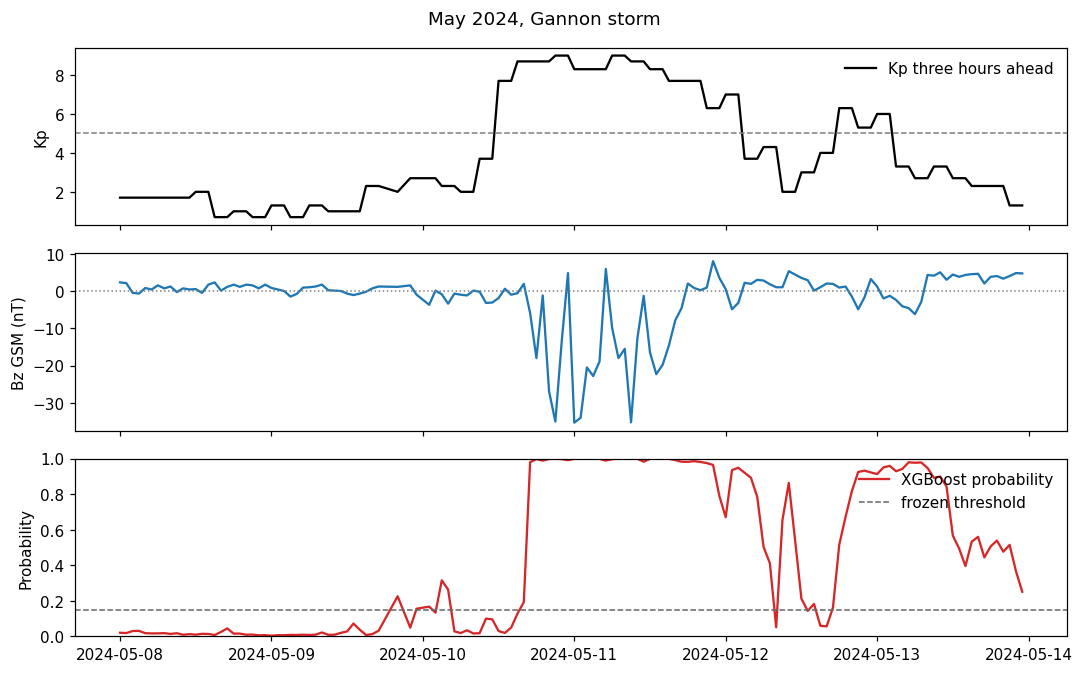

In [25]:
def plot_case(start, end, title):
    window = scored[(scored["time"] >= start) & (scored["time"] < end)].copy()
    if window.empty:
        print(f"No test rows in {title}")
        return
    clock = window["time"].dt.tz_convert("UTC").dt.tz_localize(None)
    fig, axes = plt.subplots(3, 1, figsize=(10, 6.2), sharex=True)
    axes[0].plot(clock, window["kp_in_3h"], color="black", label="Kp three hours ahead")
    axes[0].axhline(5, color="0.5", linestyle="--", linewidth=1)
    axes[0].set_ylabel("Kp")
    axes[0].legend(frameon=False, loc="upper right")
    axes[1].plot(clock, window["bz_gsm"], color="C0")
    axes[1].axhline(0, color="0.5", linestyle=":", linewidth=1)
    axes[1].set_ylabel("Bz GSM (nT)")
    axes[2].plot(clock, window["proba"], color="C3", label="XGBoost probability")
    axes[2].axhline(proba_threshold, color="0.4", linestyle="--", linewidth=1, label="frozen threshold")
    axes[2].set_ylabel("Probability")
    axes[2].set_ylim(0, 1)
    axes[2].legend(frameon=False, loc="upper right")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_case(pd.Timestamp("2022-02-01", tz="UTC"), pd.Timestamp("2022-02-06", tz="UTC"), "February 2022, Starlink storm")
plot_case(pd.Timestamp("2024-05-08", tz="UTC"), pd.Timestamp("2024-05-14", tz="UTC"), "May 2024, Gannon storm")


## Blocked time-series validation

Five expanding windows on the years before 2021. `TimeSeriesSplit` leaves a 6-row gap. Each fold also drops any fit row within 6 hours of its inner validation block, and any inner-validation row within 6 hours of the fold test, so a missing hour cannot shrink the purge. The probability cut is chosen inside the fold, on that inner block, and then applied to the fold test. The 2021-onward test set is not used here.


In [26]:
pretest = df[df["time"] < VAL_END].sort_values("time").reset_index(drop=True)
splitter = TimeSeriesSplit(n_splits=5, gap=6)
fold_rows = []

for fold, (train_pos, test_pos) in enumerate(splitter.split(pretest), start=1):
    cut = int(len(train_pos) * 0.85)
    fit_pos = train_pos[:cut]
    inner_pos = train_pos[cut + 6 :]
    if len(inner_pos) < 24 or len(test_pos) < 24:
        continue
    inner_start = pretest.loc[inner_pos[0], "time"]
    test_start = pretest.loc[test_pos[0], "time"]
    fit_time = pretest.loc[fit_pos, "time"].to_numpy()
    fit_pos = fit_pos[fit_time < inner_start - GAP]
    inner_time = pretest.loc[inner_pos, "time"].to_numpy()
    inner_pos = inner_pos[inner_time < test_start - GAP]
    y_fit = pretest.loc[fit_pos, "storm"]
    if y_fit.sum() == 0 or len(fit_pos) < 1000:
        continue
    fold_model = make_model(y_fit)
    fold_model.fit(
        pretest.loc[fit_pos, FEATURE_COLS],
        y_fit,
        eval_set=[(pretest.loc[inner_pos, FEATURE_COLS], pretest.loc[inner_pos, "storm"])],
        verbose=False,
    )
    inner_proba = fold_model.predict_proba(pretest.loc[inner_pos, FEATURE_COLS])[:, 1]
    fold_threshold, _ = choose_probability_threshold(pretest.loc[inner_pos, "storm"], inner_proba)
    test_proba = fold_model.predict_proba(pretest.loc[test_pos, FEATURE_COLS])[:, 1]
    y_test = pretest.loc[test_pos, "storm"]
    pred = test_proba >= fold_threshold
    fold_rows.append(
        {
            "fold": fold,
            "test_start": pretest.loc[test_pos[0], "time"].date(),
            "test_end": pretest.loc[test_pos[-1], "time"].date(),
            "tss": true_skill_score(y_test, pred),
            "pr_auc": average_precision_score(y_test, test_proba),
            "roc_auc": roc_auc_score(y_test, test_proba),
            "threshold": fold_threshold,
        }
    )

cv_results = pd.DataFrame(fold_rows)
cv_results


,fold,test_start,test_end,tss,pr_auc,roc_auc,threshold
0,1,1999-05-10,2003-12-16,0.600159,0.406410,0.873744,0.34
1,2,2003-12-16,2008-03-25,0.678420,0.485550,0.944357,0.62
2,3,2008-03-25,2012-07-01,0.786924,0.474463,0.965730,0.36
3,4,2012-07-02,2016-10-06,0.741737,0.470598,0.941020,0.24
4,5,2016-10-06,2020-12-31,0.810325,0.387232,0.966924,0.39


In [27]:
print(
    f"Blocked CV  TSS {cv_results['tss'].mean():.3f} ± {cv_results['tss'].std(ddof=1):.3f}   "
    f"PR-AUC {cv_results['pr_auc'].mean():.3f} ± {cv_results['pr_auc'].std(ddof=1):.3f}"
)
print(
    "Held-out test: "
    + ", ".join(
        f"{row.model} TSS {row.tss:.3f}"
        for row in metrics.itertuples(index=False)
    )
)
print(
    "Onset recall: "
    + ", ".join(f"{row.model} {row.onset_recall:.3f}" for row in onset_table.itertuples(index=False))
)


Blocked CV  TSS 0.724 ± 0.085   PR-AUC 0.445 ± 0.045
Held-out test: persistence TSS 0.503, bz threshold TSS 0.402, xgboost TSS 0.615
Onset recall: persistence 0.000, bz threshold 0.372, xgboost 0.874


## Next

The index is not the decision. A probability of G1 still has to become drag or charging for a satellite at a given altitude and ballistic coefficient. A density model trained on observed ap and then fed a forecast of ap is the same train/serve mismatch as a demand model trained on observed weather.

The other evaluation worth adding is a cost threshold: a missed storm and a false maneuver do not have the same price, so the cut should move with the operator. Calibrated probabilities matter more than swapping XGBoost for a random forest. A forest would fit the same table and would not give this loss curve. The coupling is nonlinear, which is why boosting was the first model.
